In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import wordcloud
from textblob import TextBlob
# from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.sentiment.util import *
import jenkspy
nltk.download('stopwords')
nltk.download('wordnet')
lm = WordNetLemmatizer()

    

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
biden_tweets = pd.read_csv('Data/biden_df_civility_lables.csv')
biden_tweets

,user_id,likes,retweet_count,cleantext,class
0,1.932939e+07,73.0,4.0,joebiden enlisting list star power help close ...,2
1,1.932939e+07,226.0,14.0,celebs excited america voted blue congrats pre...,2
2,1.716932e+07,717.0,55.0,campaigning across battleground state ran grea...,2
3,2.158642e+07,22641.0,2543.0,big fight today realdonaldtrump v joebiden got...,2
4,1.191236e+07,6748.0,919.0,news outlet projected joebiden secured elector...,2
...,...,...,...,...,...
179570,1.325025e+18,0.0,0.0,joebiden uselectionresults kamalaharris http c...,1
179571,1.322222e+18,0.0,0.0,price tea china go biden get elected,2
179572,1.318598e+18,0.0,0.0,electric vehicle made lamborghini porsche bent...,2
179573,1.199519e+18,0.0,0.0,realdonaldtrump like monopoly joebiden skip ja...,1


In [7]:
def user_activity(dataframe):
    tweet_counts = dataframe.groupby('user_id').size()
    labels = tweet_counts.apply(lambda x: 'active' if x > 5 else 'less active')
    dataframe['user_activity'] = dataframe['user_id'].map(labels)
    return dataframe

def getsubjectivity(text):
    return TextBlob(text).sentiment.subjectivity
def getpolarity(text):
    return TextBlob(text).sentiment.polarity
def getAnalysis(score):
    if score <0:
        return 'negative'
    elif score == 0:
        return 'neutral'
    else:
        return 'positive'
def sentiment_analysis(tweets):
    tweets['subjectivity'] = tweets['cleantext'].apply(getsubjectivity)
    
    tweets['polarity'] = tweets['cleantext'].apply(getpolarity)
    
    tweets['analysis'] = tweets['polarity'].apply(getAnalysis)
    return tweets
def check_and_convert(value):
    if isinstance(value, float):  # Check if the value is a float
        return str(value)         # Convert float to string
    else:
        return value              # Return value unchanged if not a float


biden_tweets_activity = user_activity(biden_tweets)

In [8]:
biden_tweets_activity[biden_tweets_activity['user_activity'] == 'active'].head()

,user_id,likes,retweet_count,cleantext,class,user_activity
7,17446621.0,406.0,40.0,victory speech joebiden said understood trump ...,2,active
8,17446621.0,272.0,18.0,gabrielleunion reacted news joebiden taken lea...,2,active
9,17446621.0,515.0,38.0,hollywood star cheer joebiden take lead pennsy...,2,active
10,17446621.0,186.0,15.0,gabrielle union kerry washington eva longoria ...,2,active
11,17446621.0,73.0,1.0,jimmykimmel offered view last day gone close r...,2,active


In [6]:
print("Biden active user",biden_tweets_activity[biden_tweets_activity['user_activity'] == 'active'].shape)
print("Biden less active user",biden_tweets_activity[biden_tweets_activity['user_activity'] == 'less active'].shape)

Biden active user (96705, 6)
Biden less active user (82870, 6)


In [81]:
biden_tweets.shape

(179575, 9)

In [9]:
biden_df = sentiment_analysis(biden_tweets_activity)
biden_df.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis
0,19329393.0,73.0,4.0,joebiden enlisting list star power help close ...,2,less active,0.0000,0.00000,neutral
1,19329393.0,226.0,14.0,celebs excited america voted blue congrats pre...,2,less active,0.6625,0.49375,positive
2,17169320.0,717.0,55.0,campaigning across battleground state ran grea...,2,less active,0.7500,0.80000,positive
3,21586418.0,22641.0,2543.0,big fight today realdonaldtrump v joebiden got...,2,less active,0.1000,0.00000,neutral
4,11912362.0,6748.0,919.0,news outlet projected joebiden secured elector...,2,less active,0.0000,0.00000,neutral


In [10]:
sorted_biden = biden_df.sort_values(by=['likes', 'retweet_count'], ascending=False)
sorted_biden.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis
102,139823781.0,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.5125,0.483333,positive
19865,38362690.0,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.0000,0.000000,neutral
94,139823781.0,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.4500,0.080000,positive
90,139823781.0,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.6800,0.522500,positive
92,139823781.0,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.5625,0.100000,positive


In [94]:
sorted_biden.groupby('user_activity')[['polarity']].mean()

,polarity
user_activity,
active,0.064923
less active,0.098101


In [11]:
biden_df.analysis.value_counts()

analysis
neutral     83859
positive    65654
negative    30062
Name: count, dtype: int64

In [12]:
biden_df['class'].value_counts()

class
2    132172
1     47389
0        14
Name: count, dtype: int64

In [15]:
num_bins = 5

breaks = jenkspy.jenks_breaks(sorted_biden['likes'], n_classes= num_bins)
print(breaks)
sorted_biden['likes_category'] = pd.cut(sorted_biden['likes'], bins=breaks, labels=range(1, num_bins+1), include_lowest=True)
sorted_biden.head(1000)

[0.0, 1498.0, 8855.0, 28696.0, 74528.0, 165702.0]


,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category
102,1.398238e+08,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.512500,0.483333,positive,5
19865,3.836269e+07,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,4
94,1.398238e+08,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.450000,0.080000,positive,4
90,1.398238e+08,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.680000,0.522500,positive,4
92,1.398238e+08,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.562500,0.100000,positive,4
...,...,...,...,...,...,...,...,...,...,...
756,2.858792e+07,278.0,81.0,people think voting guy vote decency election ...,2,active,0.000000,0.000000,neutral,1
2640,4.439796e+07,278.0,64.0,joebiden celebrated abc right donaldtrump inte...,1,active,0.642857,0.317857,positive,1
12291,2.095488e+07,278.0,54.0,breaking joebiden take lead georgia vote trump...,2,active,0.650000,0.400000,positive,1
676,1.899340e+07,278.0,35.0,breaking abc news characterize joe biden appar...,2,active,0.412500,0.412500,positive,1


In [16]:
breaks = jenkspy.jenks_breaks(sorted_biden['retweet_count'], n_classes= num_bins)
print(breaks)
sorted_biden['retweet_count_category'] = pd.cut(sorted_biden['retweet_count'], bins=breaks, labels=range(1, num_bins+1), include_lowest=True)
sorted_biden.head(1000)

[0.0, 209.0, 1072.0, 2999.0, 7489.0, 20615.0]


,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category,retweet_count_category
102,1.398238e+08,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.512500,0.483333,positive,5,5
19865,3.836269e+07,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,4,5
94,1.398238e+08,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.450000,0.080000,positive,4,4
90,1.398238e+08,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.680000,0.522500,positive,4,3
92,1.398238e+08,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.562500,0.100000,positive,4,4
...,...,...,...,...,...,...,...,...,...,...,...
756,2.858792e+07,278.0,81.0,people think voting guy vote decency election ...,2,active,0.000000,0.000000,neutral,1,1
2640,4.439796e+07,278.0,64.0,joebiden celebrated abc right donaldtrump inte...,1,active,0.642857,0.317857,positive,1,1
12291,2.095488e+07,278.0,54.0,breaking joebiden take lead georgia vote trump...,2,active,0.650000,0.400000,positive,1,1
676,1.899340e+07,278.0,35.0,breaking abc news characterize joe biden appar...,2,active,0.412500,0.412500,positive,1,1


In [17]:
sorted_biden.to_csv('sorted_biden_categorical_civility.csv', index=False)

In [18]:
sorted_biden.groupby('retweet_count_category')['polarity'].mean()

/var/folders/x5/k2wknhr57b1bk7btjrfpvfbm0000gn/T/ipykernel_24485/3844585572.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sorted_biden.groupby('retweet_count_category')['polarity'].mean()


retweet_count_category
1    0.080197
2    0.088360
3    0.172905
4    0.131111
5    0.241667
Name: polarity, dtype: float64

In [80]:
sorted_biden.groupby('likes_category')['polarity'].mean()

/var/folders/x5/k2wknhr57b1bk7btjrfpvfbm0000gn/T/ipykernel_24485/1352699997.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sorted_biden.groupby('likes_category')['polarity'].mean()


likes_category
1    0.080171
2    0.137957
3    0.187300
4    0.160500
5    0.483333
Name: polarity, dtype: float64

In [19]:
sorted_biden.retweet_count_category.value_counts()

retweet_count_category
1    179183
2       349
3        32
4         9
5         2
Name: count, dtype: int64

In [20]:
sorted_biden.likes_category.value_counts()

likes_category
1    179401
2       152
3        16
4         5
5         1
Name: count, dtype: int64

In [82]:
sorted_biden.user_id.value_counts()

user_id
1.244982e+18    1259
8.742585e+08    1059
2.395433e+07     922
1.228206e+09     416
1.828681e+07     370
                ... 
2.894671e+09       1
9.531434e+07       1
1.238456e+18       1
1.234192e+08       1
1.199519e+18       1
Name: count, Length: 61201, dtype: int64

In [21]:
grouped_biden = sorted_biden.groupby(['user_id', 'analysis']).size().unstack(fill_value=0)
grouped_biden['Total_tweets'] = grouped_biden['positive'] + grouped_biden['negative']+grouped_biden['neutral']
grouped_biden ['user_polarization'] = ((grouped_biden['positive']-grouped_biden['negative']) * (
            grouped_biden['Total_tweets'] - grouped_biden['neutral'])) / pow(grouped_biden['Total_tweets'],2)
grouped_biden

analysis,negative,neutral,positive,Total_tweets,user_polarization
user_id,,,,,
1.081000e+03,0,1,0,1,0.00
2.654000e+03,0,1,4,5,0.64
3.652000e+03,0,1,0,1,0.00
4.358000e+03,0,1,0,1,0.00
5.608000e+03,0,1,0,1,0.00
...,...,...,...,...,...
1.325492e+18,0,1,0,1,0.00
1.325502e+18,0,0,1,1,1.00
1.325533e+18,0,0,1,1,1.00


In [83]:
sorted_trump = pd.read_csv('sorted_trump_categorical_civility.csv')
grouped_trump = sorted_trump.groupby(['user_id', 'analysis']).size().unstack(fill_value=0)
grouped_trump['Total_tweets'] = grouped_trump['positive'] + grouped_trump['negative']+grouped_trump['neutral']
grouped_trump ['user_polarization'] = ((grouped_trump['positive']-grouped_trump['negative']) * (
            grouped_trump['Total_tweets'] - grouped_trump['neutral'])) / pow(grouped_trump['Total_tweets'],2)
grouped_trump

analysis,negative,neutral,positive,Total_tweets,user_polarization
user_id,,,,,
5.310000e+02,0,0,1,1,1.000000
2.654000e+03,6,4,7,17,0.044983
3.471000e+03,0,0,1,1,1.000000
1.341000e+04,0,0,1,1,1.000000
1.341300e+04,2,0,3,5,0.200000
...,...,...,...,...,...
1.325492e+18,0,1,0,1,0.000000
1.325492e+18,0,1,0,1,0.000000
1.325521e+18,0,0,1,1,1.000000


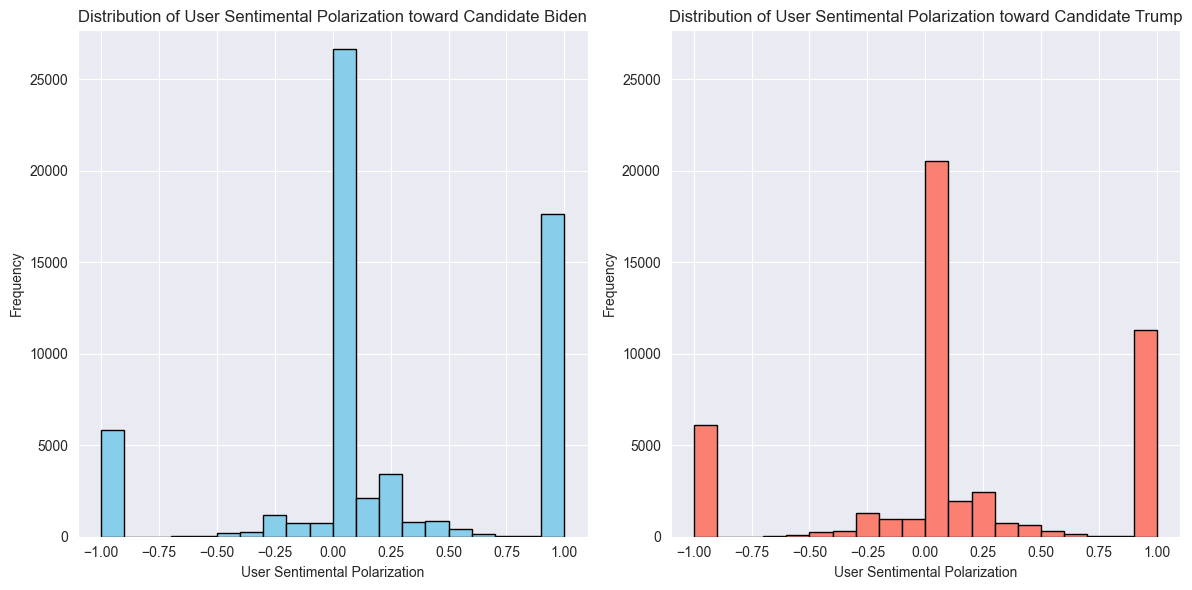

In [91]:
import matplotlib.pyplot as plt

# Create a figure with two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Plot histogram for Biden
axs[0].hist(grouped_biden['user_polarization'], bins=20, color='skyblue', edgecolor='black')

# Add labels and title for the first subplot
axs[0].set_xlabel('User Sentimental Polarization')
axs[0].set_ylabel('Frequency')
axs[0].set_title('Distribution of User Sentimental Polarization toward Candidate Biden')

# Plot histogram for Trump
axs[1].hist(grouped_trump['user_polarization'], bins=20, color='salmon', edgecolor='black')

# Add labels and title for the second subplot
axs[1].set_xlabel('User Sentimental Polarization')
axs[1].set_ylabel('Frequency')
axs[1].set_title('Distribution of User Sentimental Polarization toward Candidate Trump')

# Calculate maximum frequency between the two datasets
max_freq = max(max(np.histogram(grouped_biden['user_polarization'], bins=20)[0]),
               max(np.histogram(grouped_trump['user_polarization'], bins=20)[0]))

# Set the same frequency scale for both subplots
for ax in axs:
    ax.set_ylim(0, max_freq+1000)

# Adjust layout
plt.tight_layout()

# Save the plot
plt.savefig('user_polarization_distribution_side_by_side.png')

# Show the plot
plt.show()




# Some Civility analysis

In [23]:
sorted_biden.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category,retweet_count_category
102,139823781.0,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.5125,0.483333,positive,5,5
19865,38362690.0,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.0000,0.000000,neutral,4,5
94,139823781.0,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.4500,0.080000,positive,4,4
90,139823781.0,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.6800,0.522500,positive,4,3
92,139823781.0,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.5625,0.100000,positive,4,4


In [24]:
sorted_biden.groupby('class')['polarity'].mean()

class
0    0.050247
1    0.046100
2    0.092476
Name: polarity, dtype: float64

In [25]:
sorted_biden.groupby('class')['subjectivity'].mean()

class
0    0.397854
1    0.287198
2    0.306906
Name: subjectivity, dtype: float64

In [66]:
final_biden= sorted_biden.groupby('user_id').agg({'class': 'mean', 'polarity': 'mean', 'likes': 'sum', 'retweet_count': 'sum'})


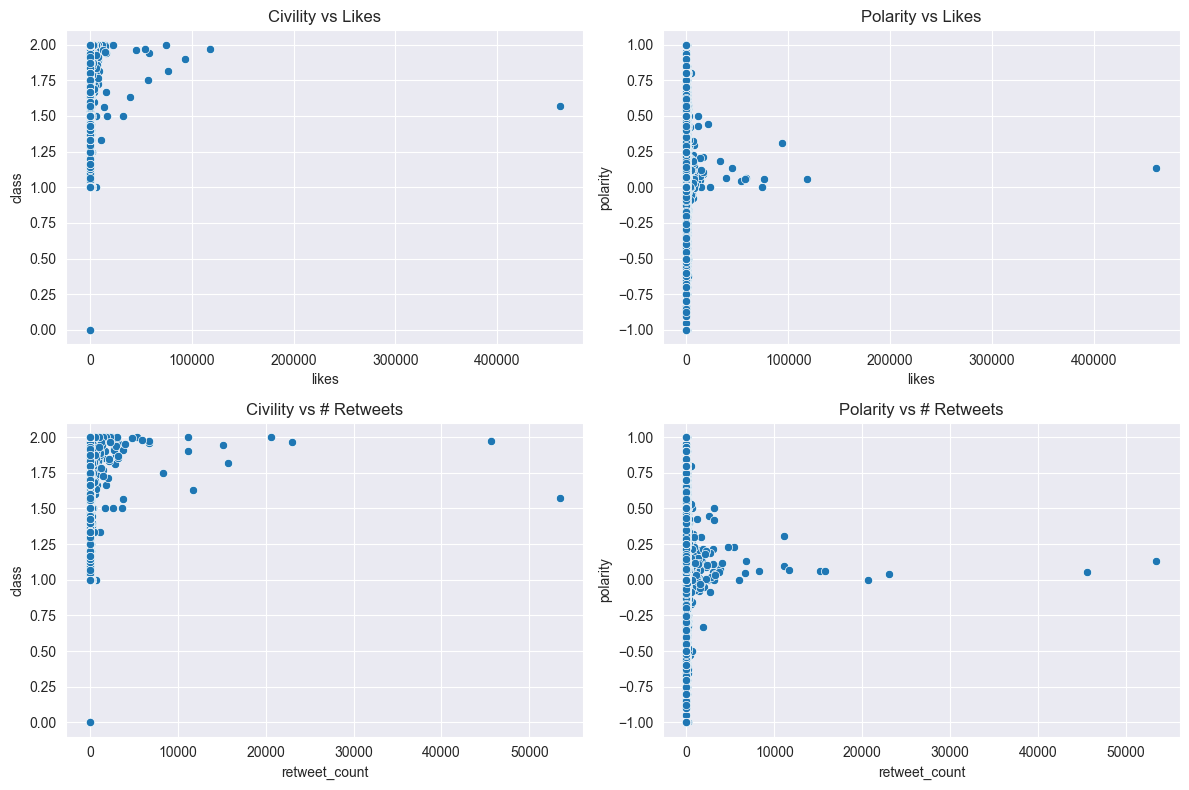

In [70]:


# Scatter plot for civility (class) vs likes and polarity vs likes
plt.figure(figsize=(12, 8))

# Civility vs Likes
plt.subplot(2, 2, 1)
sns.scatterplot(x='likes', y='class', data=final_biden)
plt.title('Civility vs Likes')

# Polarity vs Likes
plt.subplot(2, 2, 2)
sns.scatterplot(x='likes', y='polarity', data=final_biden)
plt.title('Polarity vs Likes')

plt.subplot(2, 2, 3)
sns.scatterplot(x='retweet_count', y='class', data=final_biden)
plt.title('Civility vs # Retweets')

plt.subplot(2, 2, 4)
sns.scatterplot(x='retweet_count', y='polarity', data=final_biden)
plt.title('Polarity vs # Retweets')

plt.tight_layout()  # Adjust layout to prevent overlap

# Save the combined plot
plt.savefig('combined_scatter_plots_biden.png')
plt.show()


In [71]:
#final_biden_filtered = final_biden[(final_biden['likes'] > 100) & (final_biden['class'] < 1.999) & (final_biden['class'] > 0.001) & (final_biden['likes'] < 400000)]

final_biden_filtered = final_biden[ (final_biden['retweet_count'] < 40000) & (final_biden['class'] > 0.001) & (final_biden['likes'] < 400000)]

final_biden_filtered

,class,polarity,likes,retweet_count
user_id,,,,
1.081000e+03,1.0,0.000000,72.0,5.0
2.654000e+03,1.8,0.083333,2.0,1.0
3.652000e+03,2.0,0.000000,4.0,0.0
4.358000e+03,2.0,0.000000,0.0,0.0
5.608000e+03,2.0,0.000000,0.0,0.0
...,...,...,...,...
1.325492e+18,2.0,0.000000,0.0,0.0
1.325502e+18,2.0,0.500000,0.0,0.0
1.325533e+18,2.0,0.250000,0.0,0.0


In [95]:
final_biden_filtered['likes'].sum()

1700034.0

In [98]:
final_biden_filtered.loc[final_biden_filtered['polarity'] != 0, 'likes'].sum()

1476834.0

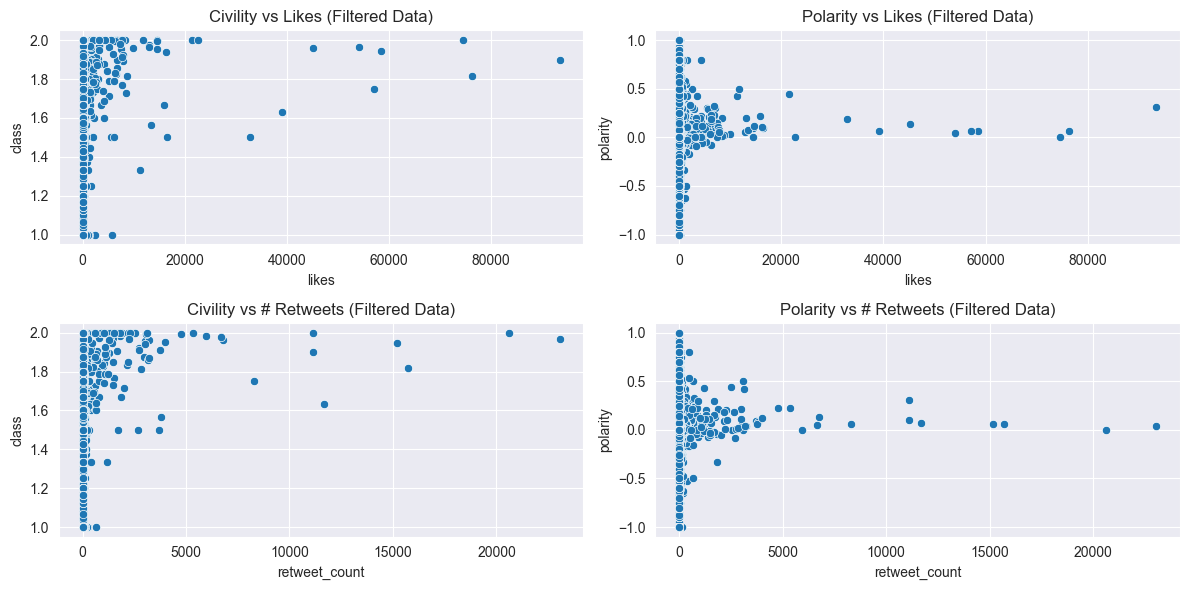

In [75]:

plt.figure(figsize=(12, 6))

# Civility vs Likes (Filtered Data)
plt.subplot(2, 2, 1)
sns.scatterplot(x='likes', y='class', data=final_biden_filtered)
plt.title('Civility vs Likes (Filtered Data)')

# Polarity vs Likes (Filtered Data)
plt.subplot(2, 2, 2)
sns.scatterplot(x='likes', y='polarity', data=final_biden_filtered)
plt.title('Polarity vs Likes (Filtered Data)')

plt.subplot(2, 2, 3)
sns.scatterplot(x='retweet_count', y='class', data=final_biden_filtered)
plt.title('Civility vs # Retweets (Filtered Data)')

plt.subplot(2, 2, 4)
sns.scatterplot(x='retweet_count', y='polarity', data=final_biden_filtered)
plt.title('Polarity vs # Retweets (Filtered Data)')

plt.tight_layout()  # Adjust layout to prevent overlap

# Save the combined plot for filtered data
plt.savefig('combined_scatter_plots_filtered.png')
plt.show()




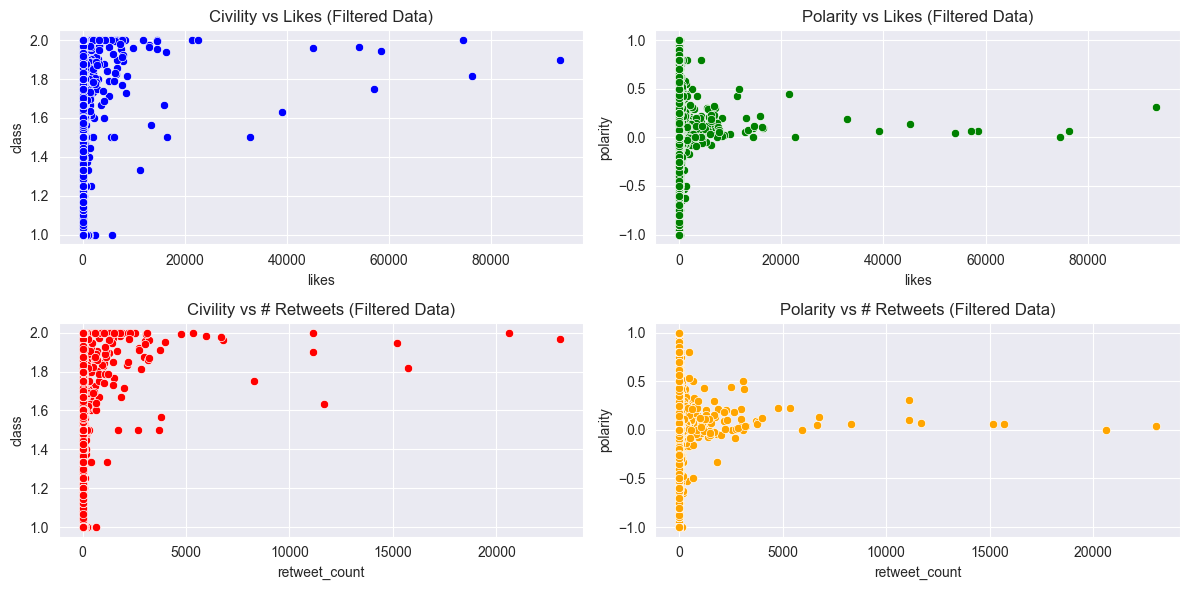

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

# Civility vs Likes (Filtered Data)
plt.subplot(2, 2, 1)
sns.scatterplot(x='likes', y='class', color='blue', data=final_biden_filtered)
plt.title('Civility vs Likes (Filtered Data)')

# Polarity vs Likes (Filtered Data)
plt.subplot(2, 2, 2)
sns.scatterplot(x='likes', y='polarity', color='green', data=final_biden_filtered)
plt.title('Polarity vs Likes (Filtered Data)')

plt.subplot(2, 2, 3)
sns.scatterplot(x='retweet_count', y='class', color='red', data=final_biden_filtered)
plt.title('Civility vs # Retweets (Filtered Data)')

plt.subplot(2, 2, 4)
sns.scatterplot(x='retweet_count', y='polarity', color='orange', data=final_biden_filtered)
plt.title('Polarity vs # Retweets (Filtered Data)')

plt.tight_layout()  # Adjust layout to prevent overlap

# Save the combined plot for filtered data
plt.savefig('combined_scatter_plots_filtered_biden_color.png')
plt.show()


 # Is there a correlation between user activity or the number of tweets and the tendency of users to employ offensive language?

In [102]:
biden_OL = sorted_biden.groupby('user_id').agg({'cleantext':'size', 'class': 'mean', 'likes': 'sum', 'retweet_count': 'sum'})

In [136]:
trump_OL = sorted_trump.groupby('user_id').agg({'cleantext':'size', 'class': 'mean', 'likes': 'sum', 'retweet_count': 'sum'})

In [103]:
biden_OL

,cleantext,class,likes,retweet_count
user_id,,,,
1.081000e+03,1,1.0,72.0,5.0
2.654000e+03,5,1.8,2.0,1.0
3.652000e+03,1,2.0,4.0,0.0
4.358000e+03,1,2.0,0.0,0.0
5.608000e+03,1,2.0,0.0,0.0
...,...,...,...,...
1.325492e+18,1,2.0,0.0,0.0
1.325502e+18,1,2.0,0.0,0.0
1.325533e+18,1,2.0,0.0,0.0


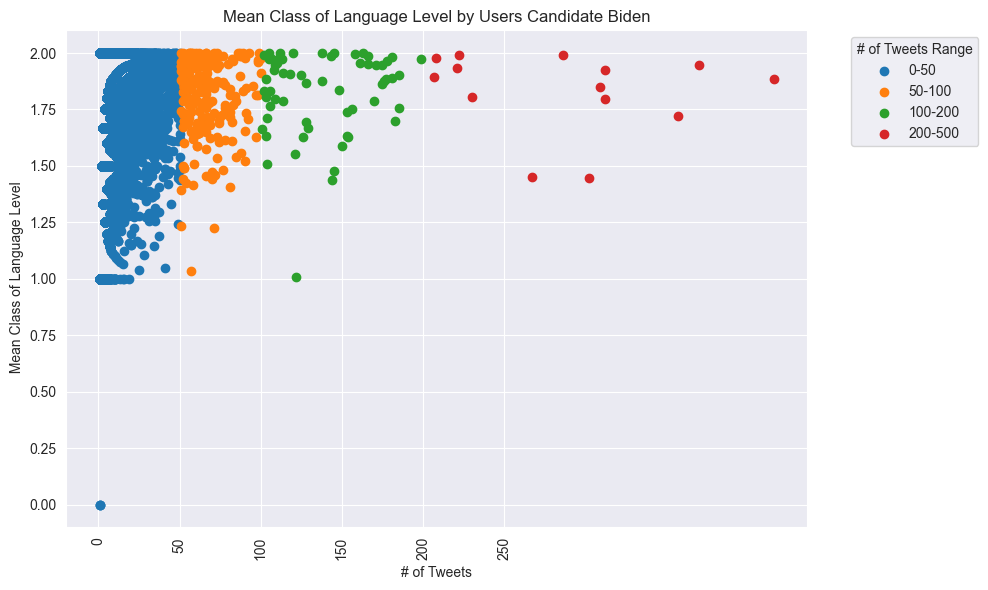

In [140]:
ranges = [(0, 50), (50, 100), (100, 200), (200, 500)]

# Create a single figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Iterate over ranges
for start, end in ranges:
    biden_OL_filter = biden_OL[(biden_OL['cleantext'] > start) & (biden_OL['cleantext'] <= end)]
    ax.scatter(biden_OL_filter['cleantext'], biden_OL_filter['class'], label=f'{start}-{end}')
    
# Add labels and title
ax.set_xlabel('# of Tweets')
ax.set_ylabel(' Mean Class of Language Level')
ax.set_title('Mean Class of Language Level by Users Candidate Biden')
ax.set_xticks(range(0, 300, 50))
ax.legend(title='# of Tweets Range', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('MeanClassLanguageLevel_Biden.png')
# Show plot
plt.show()

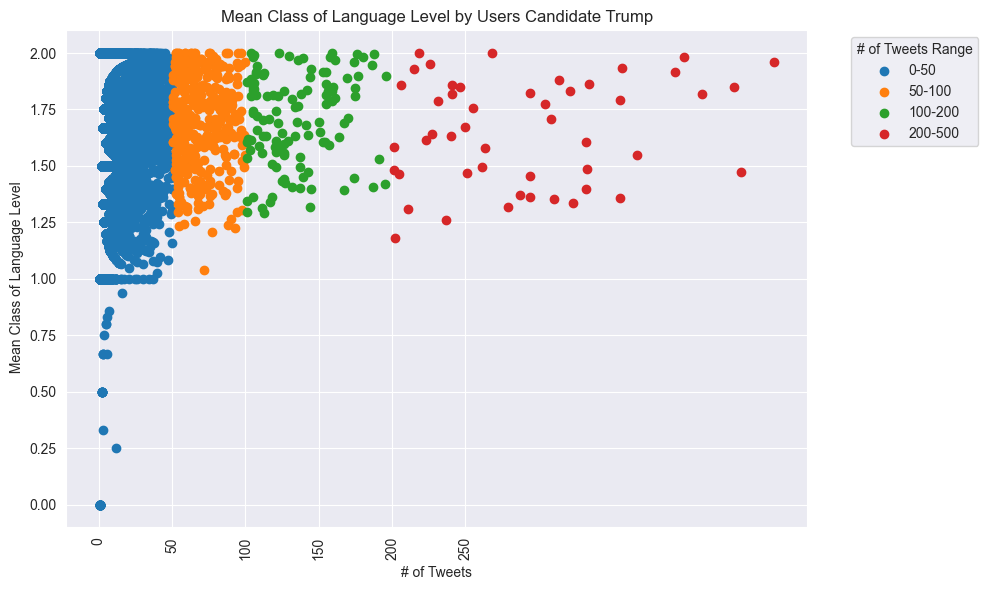

In [139]:
ranges = [(0, 50), (50, 100), (100, 200), (200, 500)]

# Create a single figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Iterate over ranges
for start, end in ranges:
    trump_OL_filter = trump_OL[(trump_OL['cleantext'] > start) & (trump_OL['cleantext'] <= end)]
    ax.scatter(trump_OL_filter['cleantext'], trump_OL_filter['class'], label=f'{start}-{end}')
    
# Add labels and title
ax.set_xlabel('# of Tweets')
ax.set_ylabel(' Mean Class of Language Level')
ax.set_title('Mean Class of Language Level by Users Candidate Trump')
ax.set_xticks(range(0, 300, 50))
ax.legend(title='# of Tweets Range', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('MeanClassLanguageLevel_Trump.png')
# Show plot
plt.show()

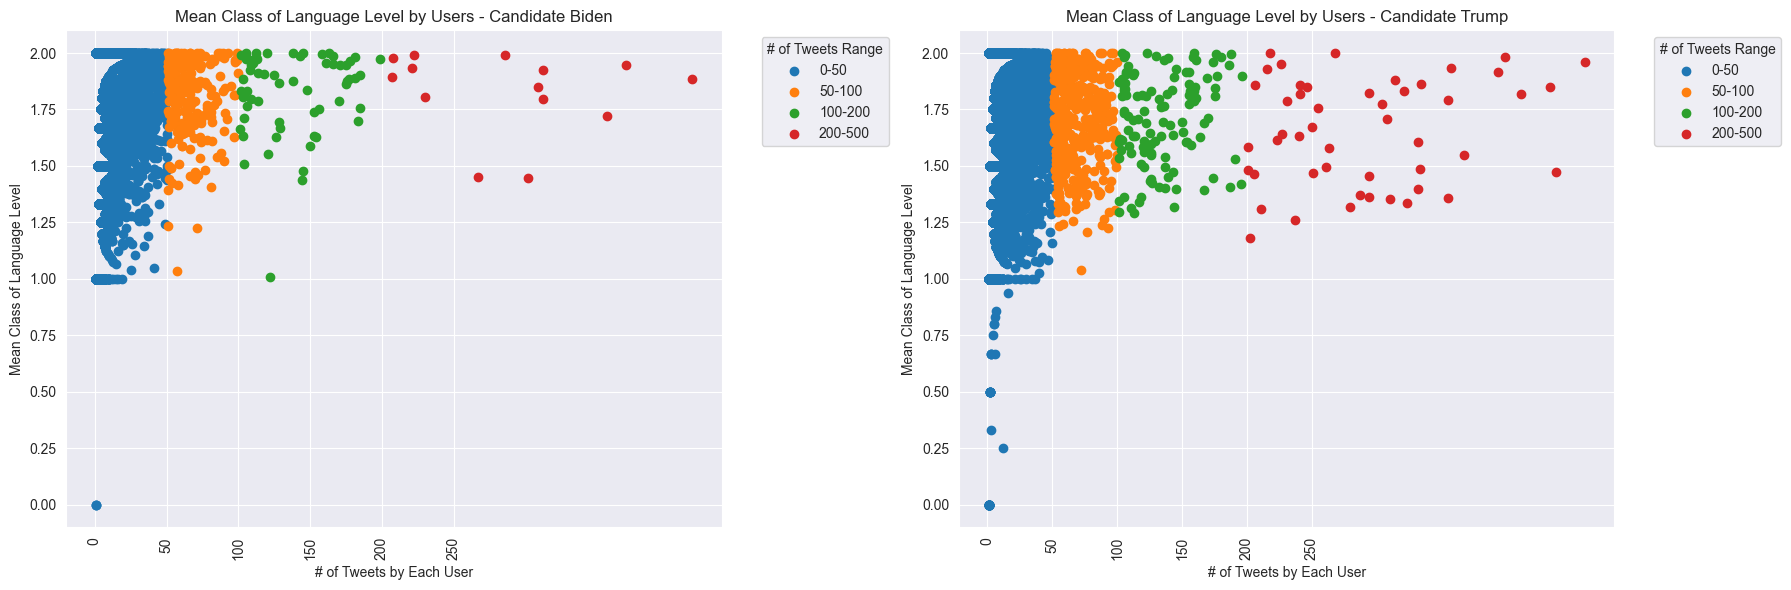

In [144]:
ranges = [(0, 50), (50, 100), (100, 200), (200, 500)]

# Create a single figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Iterate over ranges for Biden
for start, end in ranges:
    biden_OL_filter = biden_OL[(biden_OL['cleantext'] > start) & (biden_OL['cleantext'] <= end)]
    ax1.scatter(biden_OL_filter['cleantext'], biden_OL_filter['class'], label=f'{start}-{end}')

# Add labels and title for Biden
ax1.set_xlabel('# of Tweets by Each User')
ax1.set_ylabel('Mean Class of Language Level')
ax1.set_title('Mean Class of Language Level by Users - Candidate Biden')
ax1.set_xticks(range(0, 300, 50))
ax1.legend(title='# of Tweets Range', bbox_to_anchor=(1.05, 1), loc='upper left')
ax1.tick_params(axis='x', rotation=90)

# Iterate over ranges for Trump
for start, end in ranges:
    trump_OL_filter = trump_OL[(trump_OL['cleantext'] > start) & (trump_OL['cleantext'] <= end)]
    ax2.scatter(trump_OL_filter['cleantext'], trump_OL_filter['class'], label=f'{start}-{end}')

# Add labels and title for Trump
ax2.set_xlabel('# of Tweets by Each User')
ax2.set_ylabel('Mean Class of Language Level')
ax2.set_title('Mean Class of Language Level by Users - Candidate Trump')
ax2.set_xticks(range(0, 300, 50))
ax2.legend(title='# of Tweets Range', bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.savefig('MeanClassLanguageLevel_Biden_Trump_SideBySide.png',dpi=300)
# Show plot
plt.show()